In [54]:
import os
import operator
from typing import List, Annotated,Any,Dict,TypedDict
from pydantic import BaseModel,Field
from langchain_community.vectorstores import FAISS,Chroma
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.documents import Document
from langgraph.graph import StateGraph,START,END
from IPython.display import Image, display
from langgraph.prebuilt import create_react_agent
from langgraph.graph import add_messages
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.tools import Tool
from langchain_community.document_loaders import TextLoader
from langchain_community.document_loaders import FireCrawlLoader
from langchain_core.prompts import ChatPromptTemplate

In [55]:
from dotenv import load_dotenv

load_dotenv()
os.environ['FIRECRAWL_API_KEY'] = os.getenv('FIRECRAWL_API_KEY')

In [56]:
class ResearchState(BaseModel):
    original_query: str
    sub_questions: List[str] = []
    is_sufficient: bool = False
    evidence_bank: Annotated[List[Dict[str, Any]], operator.add] = []
    audit_logs: Annotated[List[str], operator.add] = []
    research_loops: int = 0
    final_report: str = ""  

In [66]:
# Define Pydantic schema for structured planner output
class PlannerOutput(BaseModel):
    sub_questions: list[str] = Field(
        description="List of 3 to 6 targeted, distinct sub-questions for parallel research."
    )

def planner(state: ResearchState) -> dict:
    prompt = f"""You are the Lead Strategic Research Planner for DeepDive, an advanced multi-agent research system.
Your job is to take a user research query and break it down into a targeted set of **actual interrogative questions** (each must be a complete sentence ending with a question mark '?').

Guidelines for decomposition:
1. **Interrogative Format:** Every sub-question MUST be phrased as a clear question starting with words like 'What', 'How', 'Why', 'Which', or 'In what ways', and MUST end with a question mark '?'.
2. **Adaptive Scope:** Match the depth and technical complexity of the user's query:
   - For foundational overview questions, ask core conceptual and architectural questions.
   - For complex queries, ask specific questions about benchmarks, failure modes, or trade-offs.
3. **Independence:** Each question must cover a distinct angle so researcher agents can work in parallel without overlapping work.

User Question: {state.original_query}"""

    # 1. Use standard Gemini Flash model with structured output bound to Pydantic
    llm = ChatGoogleGenerativeAI(model="gemini-3.8-flash", temperature=0.2)
    structured_llm = llm.with_structured_output(PlannerOutput)

    # 2. Invoke structured LLM
    planner_result: PlannerOutput = structured_llm.invoke(prompt)
    sub_questions = planner_result.sub_questions

    # 3. Log execution
    log_entry = (
        f"[Planner] Generated {len(sub_questions)} sub-questions for query: "
        f"'{state.original_query}'"
    )

    # 4. Return standard state updates dictionary for LangGraph
    return {
        "sub_questions": sub_questions,
        "audit_logs": [log_entry],
        "research_loops": 0,
    }

In [72]:
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")


def _extract_clean_sub_questions(sub_questions: List[Any]) -> List[str]:
    """Filters out corrupted debug strings and non-string elements."""
    clean_questions = []
    for sq in sub_questions:
        if isinstance(sq, str) and not sq.startswith("(") and "tool_calls" not in sq and "usage_metadata" not in sq:
            clean_questions.append(sq)
        elif isinstance(sq, dict) and "text" in sq:
            clean_questions.append(sq["text"])
    return clean_questions


def _process_search_item(sub_question: str, item: Dict[str, Any]) -> tuple[List[Dict[str, Any]], List[str]]:
    """Extracts page content or fallback snippet for a search item."""
    url = item.get("url")
    if not isinstance(item, dict) or not url or item.get("score", 1.0) < 0.7:
        return [], []

    logs = [f"[Researcher] Scraping clean content from: {url}"]
    try:
        loader = FireCrawlLoader(url=url, mode="scrape")
        documents = loader.load()
        evidence = [
            {
                "sub_question": str(sub_question),
                "source_url": url,
                "title": doc.metadata.get("title", item.get("title", "Untitled Source")),
                "content": doc.page_content.strip(),
            }
            for doc in documents
            if doc.page_content and doc.page_content.strip()
        ]
        return evidence, logs
    except Exception as e:
        logs.append(f"[Researcher] FireCrawl warning for {url}: {str(e)}")
        fallback = item.get("content") or item.get("snippet")
        if fallback:
            return [{
                "sub_question": str(sub_question),
                "source_url": url,
                "title": item.get("title", "Untitled Source"),
                "content": fallback,
            }], logs

    return [], logs


def _fetch_sub_question_evidence(tavily_tool: TavilySearchResults, sub_question: str) -> tuple[List[Dict[str, Any]], List[str]]:
    """Executes search and processing for a single sub-question."""
    evidence, logs = [], [f"[Researcher] Searching Tavily for: '{sub_question}'"]
    try:
        response = tavily_tool.invoke(sub_question)
        if not isinstance(response, list):
            return evidence, logs

        for item in response:
            item_evidence, item_logs = _process_search_item(sub_question, item)
            evidence.extend(item_evidence)
            logs.extend(item_logs)
    except Exception as e:
        logs.append(f"[Researcher] Tavily error for '{sub_question}': {str(e)}")

    return evidence, logs


def _index_evidence_to_chroma(gathered_evidence: List[Dict[str, Any]]) -> str:
    """Indexes evidence documents into Chroma DB without raising exceptions."""
    if not gathered_evidence:
        return "[Researcher] No new evidence chunks to index."

    docs = [
        Document(
            page_content=item["content"],
            metadata={
                "sub_question": item["sub_question"],
                "source_url": item["source_url"],
                "title": item["title"],
            },
        )
        for item in gathered_evidence
    ]

    try:
        Chroma.from_documents(documents=docs, embedding=embeddings, persist_directory="./chroma_db")
        return f"[Researcher] Successfully indexed {len(docs)} chunks into local Chroma DB."
    except Exception as e:
        return f"[Researcher] Vector store indexing warning: {str(e)}"


def researcher(state: ResearchState) -> dict:
    tavily_tool = TavilySearchResults(max_results=3)
    gathered_evidence = []
    audit_logs = []

    clean_sub_questions = _extract_clean_sub_questions(state.sub_questions)

    for sub_question in clean_sub_questions:
        evidence, logs = _fetch_sub_question_evidence(tavily_tool, sub_question)
        gathered_evidence.extend(evidence)
        audit_logs.extend(logs)

    index_log = _index_evidence_to_chroma(gathered_evidence)
    audit_logs.append(index_log)
    audit_logs.append(f"[Researcher] Gathered {len(gathered_evidence)} new evidence chunks.")

    return {
        "evidence_bank": gathered_evidence,
        "audit_logs": audit_logs,
    }

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 851.67it/s]


In [59]:


class VerificationResult(BaseModel):
    is_sufficient: bool = Field(
        description="True if the evidence bank comprehensively answers all sub-questions with high factual backing. False if major gaps or thin evidence remain."
    )
    gaps: List[str] = Field(
        description="List of missing information, unverified claims, or specific sub-questions that require deeper research."
    )
    feedback: str = Field(
        description="A concise evaluation summary of the evidence quality and credibility."
    )

VERIFIER_SYSTEM_PROMPT = """You are the Senior Verification Auditor for DeepDive. 
Your role is to critically cross-examine the gathered evidence against the original research question and sub-questions. 
Detect potential contradictions, unsupported claims, or shallow data. 
If critical facts are missing, mark the evidence as insufficient and list the exact gaps so the system can trigger a targeted re-search loop."""

VERIFIER_USER_PROMPT = """Original Query: {original_query}

Sub-Questions Explored: {sub_questions}

Gathered Evidence Bank:
{evidence_summary}

Evaluate the evidence rigor and return your structured verification assessment."""

In [74]:
def verifier(state: ResearchState) -> Dict[str, Any]:
    audit_logs = ["[Verifier] Starting semantic cross-examination via vector retrieval..."]
    
    # 1. Connect to the local Chroma vector store populated by the Researcher
    embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
    try:
        vectorstore = Chroma(
            persist_directory="./chroma_db", 
            embedding_function=embeddings
        )
        retriever = vectorstore.as_retriever(search_kwargs={"k": 3})
    except Exception as e:
        audit_logs.append(f"[Verifier] Warning: Could not load Chroma DB ({str(e)}). Falling back to raw state evidence.")
        retriever = None

    # 2. Retrieve top relevant chunks per sub-question
    retrieved_docs = []
    clean_sub_questions = [str(q) for q in state.sub_questions if isinstance(q, str)]

    if retriever:
        for sq in clean_sub_questions:
            docs = retriever.invoke(sq)
            retrieved_docs.extend(docs)
    else:
        # Fallback if retriever fails
        retrieved_docs = [
            Document(page_content=item.get("content", ""), metadata=item)
            for item in state.evidence_bank
        ]

    # Deduplicate retrieved documents based on source URL or content snippet
    unique_docs = {doc.page_content[:100]: doc for doc in retrieved_docs}.values()

    # 3. Format lean evidence summary for the verifier prompt
    evidence_summary = "\n".join([
        f"- Sub-Q Match: {doc.metadata.get('sub_question', 'N/A')}\n"
        f"  Source: {doc.metadata.get('source_url', 'N/A')}\n"
        f"  Title: {doc.metadata.get('title', 'N/A')}\n"
        f"  Snippet: {doc.page_content[:400]}...\n"
        for doc in unique_docs
    ])
    
    llm = ChatGoogleGenerativeAI(model="gemini-3.8-flash", temperature=0.0)
    structured_llm = llm.with_structured_output(VerificationResult)
    
    verifier_prompt = ChatPromptTemplate.from_messages([
        ("system", VERIFIER_SYSTEM_PROMPT),
        ("user", VERIFIER_USER_PROMPT)
    ])
    verifier_chain = verifier_prompt | structured_llm
    
    result: VerificationResult = verifier_chain.invoke({
        "original_query": state.original_query,
        "sub_questions": ", ".join(clean_sub_questions),
        "evidence_summary": evidence_summary or "No relevant evidence found."
    })
    
    audit_logs.append(f"[Verifier] Evidence sufficient: {result.is_sufficient}. Feedback: {result.feedback}")
    
    current_loops = state.research_loops + 1
    MAX_LOOPS = 3

    if not result.is_sufficient and result.gaps and current_loops < MAX_LOOPS:
        audit_logs.append(f"[Verifier] Identified gaps for re-search (Loop {current_loops}/{MAX_LOOPS}): {result.gaps}")
        updated_sub_questions = result.gaps
        is_sufficient = False
    else:
        if current_loops >= MAX_LOOPS and not result.is_sufficient:
            audit_logs.append(f"[Verifier] Max research loops ({MAX_LOOPS}) reached. Forcing synthesis.")
        is_sufficient = True
        updated_sub_questions = state.sub_questions

    return {
        "sub_questions": updated_sub_questions,
        "is_sufficient": is_sufficient,
        "audit_logs": audit_logs,
        "research_loops": current_loops,
    }

In [61]:
def route_after_verification(state: ResearchState) -> str:
    # Loop back to researcher if evidence is insufficient and max loops not reached
    if not state.is_sufficient and state.research_loops < 3:
        return "researcher"
    return "synthesizer"

In [62]:


SYNTHESIZER_SYSTEM_PROMPT = """You are the Senior Research Synthesizer for DeepDive. 
Your task is to synthesize the gathered and verified evidence bank into a comprehensive, objective, and well-structured markdown research report answering the original query.
Cite your sources using the provided source URLs inline or in a references section. Ensure the report is transparent, rigorous, and strictly grounded in the provided evidence context."""

SYNTHESIZER_USER_PROMPT = """Original Query: {original_query}

Verified Evidence Bank:
{evidence_summary}

Generate a detailed, executive-level research report based strictly on the above context."""

In [75]:
def synthesizer(state: ResearchState) -> Dict[str, Any]:
    audit_logs = ["[Synthesizer] Generating final research report via vector retrieval..."]
    
    embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
    try:
        vectorstore = Chroma(
            persist_directory="./chroma_db", 
            embedding_function=embeddings
        )
        retriever = vectorstore.as_retriever(search_kwargs={"k": 8})
        retrieved_docs = retriever.invoke(state.original_query)
    except Exception as e:
        audit_logs.append(f"[Synthesizer] Warning: Chroma retrieval failed ({str(e)}). Falling back to state.evidence_bank.")
        retrieved_docs = [
            Document(page_content=item.get("content", ""), metadata=item)
            for item in state.evidence_bank
        ]

    # Deduplicate using the content-prefix approach
    unique_docs = {doc.page_content[:100]: doc for doc in retrieved_docs}.values()
    
    evidence_summary = "\n".join([
        f"### Source: {doc.metadata.get('title', 'Unknown')}\n"
        f"- **URL:** {doc.metadata.get('source_url', 'N/A')}\n"
        f"- **Addressed Sub-Q:** {doc.metadata.get('sub_question', 'N/A')}\n"
        f"- **Content Excerpt:**\n{doc.page_content}\n"
        for doc in unique_docs
    ])
    
    llm = ChatGoogleGenerativeAI(model="gemini-3.8-flash", temperature=0.1)
    
    synth_prompt = ChatPromptTemplate.from_messages([
        ("system", SYNTHESIZER_SYSTEM_PROMPT),
        ("user", SYNTHESIZER_USER_PROMPT)
    ])
    
    synth_chain = synth_prompt | llm
    
    response = synth_chain.invoke({
        "original_query": state.original_query,
        "evidence_summary": evidence_summary or "No evidence available."
    })
    
    final_report = response.content if hasattr(response, "content") else str(response)
    audit_logs.append("[Synthesizer] Final report compiled successfully.")
    
    return {
        "final_report": final_report,
        "audit_logs": audit_logs
    }

In [76]:
graph = StateGraph(ResearchState)
graph.add_node('planner',planner)
graph.add_node('researcher',researcher)
graph.add_node('verifier',verifier)
graph.add_node('synthesizer',synthesizer)
graph.add_conditional_edges('verifier',route_after_verification,{
        "researcher": "researcher",
        "synthesizer": "synthesizer"
    })
graph.add_edge(START,'planner')
graph.add_edge('planner', 'researcher')
graph.add_edge('researcher','verifier')
graph.add_edge('synthesizer', END)
graph_builder = graph.compile()

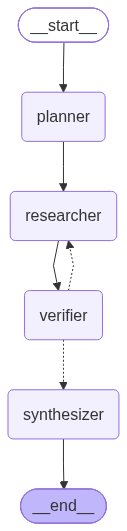

In [77]:
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [53]:
graph_builder.invoke(ResearchState(original_query='What are the latest enterprise adoption trends and architectural patterns for multi-agent LLM systems in 2026?'))

RemoteProtocolError: Server disconnected without sending a response.

In [69]:
response = graph_builder.invoke(ResearchState(original_query="What is Autonomous RAG system ?"))
print(response)

GoogleRateLimitError: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 20h22m34.846495594s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 